In [45]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt

In [46]:
from google.colab import files
uploaded = files.upload()

Saving health_dataset.csv to health_dataset (2).csv


In [47]:
import pandas as pd

df = pd.read_csv('health_dataset.csv')
df.head()

,Age,Gender,BMI,Sleep,Exercise,Steps,Water,Protein,JunkFood,Smoking,Alcohol,HealthStatus
0,18,Male,21.5,8,5,12000,3.0,85,1,0,0,Healthy
1,22,Female,22.1,7,4,9500,2.5,70,2,0,0,Healthy
2,25,Male,24.0,7,3,8000,2.5,75,2,0,0,Healthy
3,30,Female,26.5,6,2,6000,2.0,55,3,0,0,Moderate
4,35,Male,29.5,5,1,3000,1.5,40,5,1,1,Unhealthy


In [48]:
data=pd.read_csv('health_dataset.csv')


In [49]:
print(data.shape)
print(data.info())
print(data.describe())


(49, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Age           49 non-null     int64  
 1   Gender        49 non-null     object 
 2   BMI           49 non-null     float64
 3   Sleep         49 non-null     int64  
 4   Exercise      49 non-null     int64  
 5   Steps         49 non-null     int64  
 6   Water         49 non-null     float64
 7   Protein       49 non-null     int64  
 8   JunkFood      49 non-null     int64  
 9   Smoking       49 non-null     int64  
 10  Alcohol       49 non-null     int64  
 11  HealthStatus  49 non-null     object 
dtypes: float64(2), int64(8), object(2)
memory usage: 4.7+ KB
None
             Age        BMI      Sleep   Exercise         Steps      Water  \
count  49.000000  49.000000  49.000000  49.000000     49.000000  49.000000   
mean   32.244898  27.016327   6.224490   2.326531   6381.632653

In [50]:
data["Gender"] = data["Gender"].map({
    "Male":0,
    "Female":1
})

In [51]:
print(data.head())

   Age  Gender   BMI  Sleep  Exercise  Steps  Water  Protein  JunkFood  \
0   18       0  21.5      8         5  12000    3.0       85         1   
1   22       1  22.1      7         4   9500    2.5       70         2   
2   25       0  24.0      7         3   8000    2.5       75         2   
3   30       1  26.5      6         2   6000    2.0       55         3   
4   35       0  29.5      5         1   3000    1.5       40         5   

   Smoking  Alcohol HealthStatus  
0        0        0      Healthy  
1        0        0      Healthy  
2        0        0      Healthy  
3        0        0     Moderate  
4        1        1    Unhealthy  


In [52]:
X = data.drop("HealthStatus", axis=1)

y = data["HealthStatus"]

In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [54]:
model = DecisionTreeClassifier()

model.fit(X_train, y_train)

DecisionTreeClassifier()

In [55]:
predictions = model.predict(X_test)

accuracy = accuracy_score(
    y_test,
    predictions
)

print("Accuracy =", accuracy*100)

Accuracy = 100.0


In [56]:
print("HEALTH LIFESTYLE PREDICTOR")

age = int(input("Age: "))

gender = input("Gender (Male/Female): ")

height = float(input("Height in meters: "))

weight = float(input("Weight in kg: "))

sleep = float(input("Sleep hours: "))

exercise = int(input("Exercise days/week: "))

steps = int(input("Daily Steps: "))

water = float(input("Water intake (L): "))

protein = int(input("Protein intake (g): "))

junk = int(input("Junk food meals/week: "))

smoking = int(input("Smoking (1=yes,0=no): "))

alcohol = int(input("Alcohol (1=yes,0=no): "))

HEALTH LIFESTYLE PREDICTOR
Age: 20
Gender (Male/Female): male
Height in meters: 178
Weight in kg: 78
Sleep hours: 7
Exercise days/week: 3
Daily Steps: 5000
Water intake (L): 3
Protein intake (g): 50
Junk food meals/week: 4
Smoking (1=yes,0=no): 0
Alcohol (1=yes,0=no): 1


In [57]:
bmi = weight / (height ** 2)

print("BMI =", round(bmi,2))

BMI = 0.0


In [58]:
if gender.lower() == "male":
    gender = 0
else:
    gender = 1

In [59]:
user_data = [[
    age,
    gender,
    bmi,
    sleep,
    exercise,
    steps,
    water,
    protein,
    junk,
    smoking,
    alcohol
]]

result = model.predict(user_data)

print("Prediction:", result[0])

Prediction: Healthy


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [60]:
score = 100

if sleep < 7:
    score -= 10

if exercise < 3:
    score -= 15

if steps < 8000:
    score -= 10

if water < 2:
    score -= 10

if junk > 3:
    score -= 15

if smoking == 1:
    score -= 20

if alcohol == 1:
    score -= 10

print("Health Score:", score, "/100")

Health Score: 65 /100


In [61]:
print("\nRecommendations")

if sleep < 7:
    print("- Sleep 7-9 hours")

if exercise < 3:
    print("- Exercise more")

if water < 2:
    print("- Drink more water")

if protein < 60:
    print("- Increase protein intake")

if junk > 3:
    print("- Reduce junk food")


Recommendations
- Increase protein intake
- Reduce junk food


In [62]:
print("\nPossible Risks")

if bmi > 30:
    print("- Obesity")

if smoking == 1:
    print("- Lung Disease")

if junk > 4:
    print("- Diabetes")

if sleep < 6:
    print("- Fatigue")

if exercise == 0:
    print("- Heart Disease")


Possible Risks


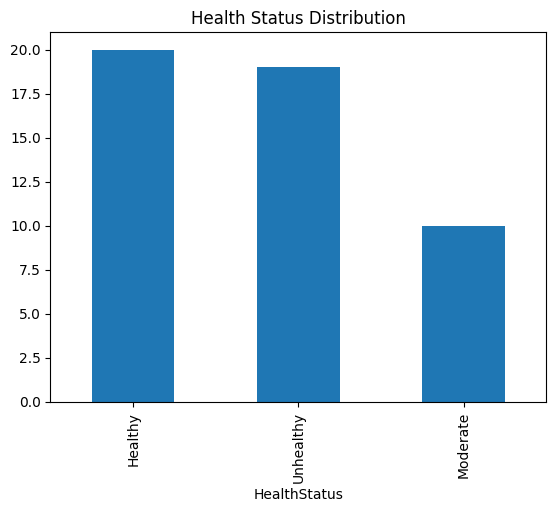

In [63]:
data["HealthStatus"].value_counts().plot(kind="bar")

plt.title("Health Status Distribution")

plt.show()

In [64]:
import joblib as jb

In [65]:
model = DecisionTreeClassifier()
model.fit(X_train, y_train)
jb.dump(model,'health_prediction.pkl')

['health_prediction.pkl']